In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score
)

In [2]:
PROJECT_DIR = Path.cwd().parent
DATA_DIR = PROJECT_DIR / "data" / "raw" / "privacy_reviews"

train = pd.read_csv(DATA_DIR / "original_12756.csv")
val = pd.read_csv(DATA_DIR / "val_1595.csv")
test = pd.read_csv(DATA_DIR / "test_1594.csv")

print("Training:", train.shape)
print("Validation:", val.shape)
print("Test:", test.shape)

Training: (12756, 3)
Validation: (1595, 3)
Test: (1594, 3)


In [3]:
# Input features (customer reviews)
X_train = train["Review"]
X_val = val["Review"]
X_test = test["Review"]

# Target labels
y_train = train["Label"]
y_val = val["Label"]
y_test = test["Label"]

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))

print("\nTarget classes:", sorted(y_train.unique()))

Training samples: 12756
Validation samples: 1595
Testing samples: 1594

Target classes: [np.int64(0), np.int64(1), np.int64(2)]


In [4]:
nb_pipeline = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            max_features=10000,
            ngram_range=(1, 2),
            min_df=2,
            sublinear_tf=True
        )
    ),
    (
        "classifier",
        MultinomialNB(alpha=1.0)
    )
])

print("Naive Bayes pipeline created successfully!")

Naive Bayes pipeline created successfully!


In [5]:
nb_pipeline.fit(X_train, y_train)

print("Naive Bayes model training completed!")

Naive Bayes model training completed!


In [6]:
# Predict labels for validation reviews
y_val_pred = nb_pipeline.predict(X_val)

# Calculate accuracy
val_accuracy = accuracy_score(y_val, y_val_pred)

print("Naive Bayes Validation Accuracy:",
      round(val_accuracy * 100, 2), "%")

# Detailed classification report
print("\nClassification Report:\n")

print(classification_report(
    y_val,
    y_val_pred,
    labels=[0, 1, 2],
    target_names=[
        "Feature Request",
        "Bug Report",
        "Privacy-Irrelevant"
    ],
    zero_division=0
))

Naive Bayes Validation Accuracy: 84.39 %

Classification Report:

                    precision    recall  f1-score   support

   Feature Request       0.87      0.78      0.82       360
        Bug Report       0.80      0.77      0.79       421
Privacy-Irrelevant       0.85      0.91      0.88       814

          accuracy                           0.84      1595
         macro avg       0.84      0.82      0.83      1595
      weighted avg       0.84      0.84      0.84      1595



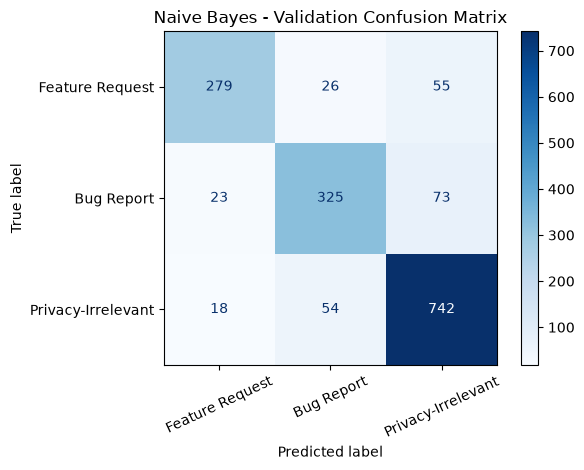

In [7]:
cm = confusion_matrix(
    y_val,
    y_val_pred,
    labels=[0, 1, 2]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Feature Request",
        "Bug Report",
        "Privacy-Irrelevant"
    ]
)

disp.plot(cmap="Blues", xticks_rotation=25)

plt.title("Naive Bayes - Validation Confusion Matrix")
plt.tight_layout()
plt.show()

## Naive Bayes - Validation Results

- Dataset: Social Media Privacy Reviews
- Training samples: 12,756
- Validation samples: 1,595
- Test samples: 1,594
- Feature extraction: TF-IDF
- Classifier: Multinomial Naive Bayes
- Maximum features: 10,000
- N-gram range: (1, 2)

### Performance

- Validation Accuracy: 84.39%
- Macro Precision: 0.84
- Macro Recall: 0.82
- Macro F1-score: 0.83

### Observation

The model performs best on Privacy-Irrelevant reviews.
Feature Request and Bug Report classification have lower
recall, indicating scope for improvement.